# Hourly day-ahead electricity load forecast (local energy cooperative)

*Notebook prepared with AI assistance (Claude); I reviewed the results. It mirrors the script in this repo and is for reading the analysis step by step.*

Data: the public *Electricity consumption dataset of a local energy cooperative* (Monteiro et al., 2024, CC BY 4.0) joined with Aveiro weather. The raw CSVs are not committed here, so this notebook has two parts:

1. **Results from the committed output files** (`results.json`, `predictions.csv`). These run without the raw data and are what the outputs below show.
2. **The full pipeline**, which re-creates those files. It runs only if you place `loureiro_energy.csv` and `weather_aveiro_final.csv` in `data/` (see the README for the download link).

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline

## Part 1. Results from the saved files
Walk-forward validation: one fold per month (Dec to May), retraining before each fold, features lagged at least 24 hours so nothing from the future is used. Error is mean kWh per reporting meter per hour (units as given in the dataset).

In [2]:
res = json.load(open('results.json'))
models = ['yesterday','last_week','ridge','hgb']
pd.DataFrame({m: res[m] for m in models}).T.round(4)

,MAE,RMSE,MAPE,n
yesterday,0.0093,0.0126,9.5618,4296.0
last_week,0.0095,0.0128,9.8121,4296.0
ridge,0.0076,0.0101,8.0515,4296.0
hgb,0.0072,0.0097,7.5029,4296.0


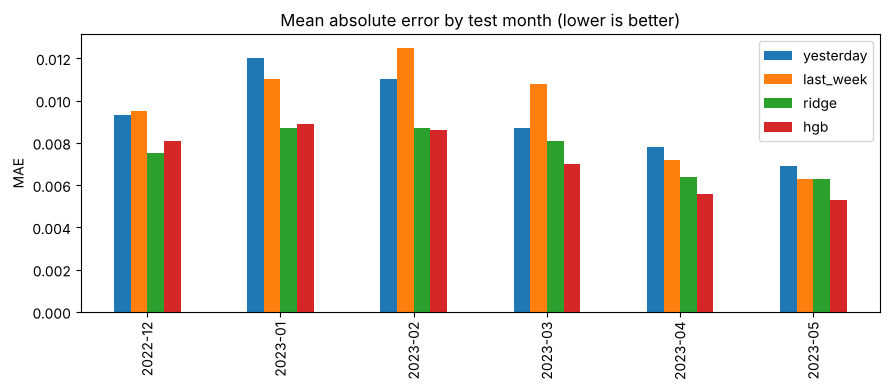

In [3]:
pm = pd.DataFrame(res['per_month_MAE']).T
pm[models].plot(kind='bar', figsize=(9,4), title='Mean absolute error by test month (lower is better)'); plt.ylabel('MAE'); plt.tight_layout(); plt.show()

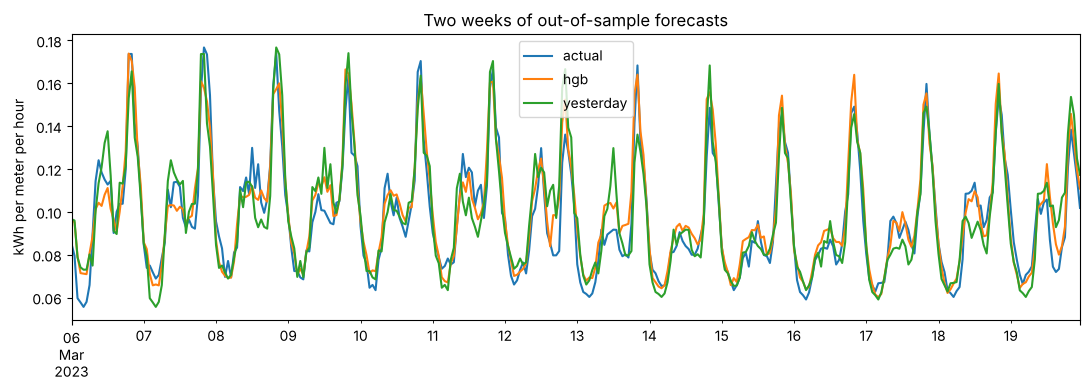

In [4]:
p = pd.read_csv('predictions.csv', index_col=0, parse_dates=True)
wk = p['2023-03-06':'2023-03-19']
ax = wk[['actual','hgb','yesterday']].plot(figsize=(11,4), title='Two weeks of out-of-sample forecasts'); ax.set_ylabel('kWh per meter per hour'); plt.tight_layout(); plt.show()

In [5]:
# Recompute the headline numbers directly from predictions.csv as a consistency check
for m in ['hgb','yesterday','last_week']:
    d = p[['actual', m]].dropna()
    print(f'{m:10s} MAE {np.mean(abs(d.actual-d[m])):.4f}   n={len(d)}')

hgb        MAE 0.0072   n=4296
yesterday  MAE 0.0093   n=4296
last_week  MAE 0.0095   n=4296


## Part 2. Full pipeline (needs the raw data)
Set up `data/` first. If the files are missing this cell prints a message and does nothing.

In [6]:
import os, sys
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
HAVE_DATA = all(os.path.exists('data/'+f) for f in ('loureiro_energy.csv','weather_aveiro_final.csv'))
print('raw data found:', HAVE_DATA)

raw data found: False


In [7]:
if HAVE_DATA:
    D = 'data'   # folder holding loureiro_energy.csv and weather_aveiro_final.csv
    e = pd.read_csv(D+'/loureiro_energy.csv', parse_dates=['Time']).set_index('Time')
    w = pd.read_csv(D+'/weather_aveiro_final.csv', parse_dates=['Time']).set_index('Time')
    act = e.notna().sum(axis=1)
    y15 = e.mean(axis=1).where(act >= 100)            # mean per reporting meter; drop rows with <100 meters
    y = y15.resample('h').mean()                       # hourly
    W = w[['Avg_Temp','Avg_Rel_Humidity','Avg_Wind_Speed','Total_Global_Rad','Quantity_Precip']].resample('h').mean()
    df = pd.DataFrame({'y': y}).join(W)
    # reporting window: stable meter coverage (Oct-2022 .. May-2023)
    df = df['2022-10-01':'2023-05-31'].copy()
    full = df.index
    df = df.reindex(pd.date_range(full.min(), full.max(), freq='h'))
    # features available at forecast time (information up to 00:00 of the day before target hour => lag>=24h)
    f = pd.DataFrame(index=df.index)
    for L in (24, 48, 168): f[f'lag{L}'] = df.y.shift(L)
    f['mean_prev24'] = df.y.shift(24).rolling(24, min_periods=12).mean()
    f['hour'] = df.index.hour; f['dow'] = df.index.dayofweek
    f['sin_h'] = np.sin(2*np.pi*f.hour/24); f['cos_h'] = np.cos(2*np.pi*f.hour/24)
    f['weekend'] = (f.dow >= 5).astype(int)
    for c in W.columns: f[c] = df[c]
    ok = df.y.notna() & f[['lag24','lag168']].notna().all(axis=1)
    X, Y = f[ok], df.y[ok]
    def metrics(t, p):
        m = ~np.isnan(p); t, p = t[m], p[m]
        return dict(MAE=float(np.mean(abs(t-p))), RMSE=float(np.sqrt(np.mean((t-p)**2))),
                    MAPE=float(np.mean(abs(t-p)/np.maximum(t,1e-3))*100), n=int(m.sum()))
    months = pd.period_range('2022-12', '2023-05', freq='M')
    res = {k: [] for k in ('yesterday','last_week','ridge','hgb')}; ys=[]; idx=[]; P={k:[] for k in res}
    for m in months:
        te = X.index.to_period('M') == m
        tr = X.index < m.start_time
        if tr.sum() < 500 or te.sum()==0: continue
        Xt, Yt, Xe, Ye = X[tr], Y[tr], X[te], Y[te]
        P['yesterday'].append(Xe.lag24); P['last_week'].append(Xe.lag168)
        r = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2,3,12))).fit(Xt.fillna(Xt.median()), Yt)
        P['ridge'].append(pd.Series(r.predict(Xe.fillna(Xt.median())), Xe.index))
        g = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_depth=5, random_state=0).fit(Xt, Yt)
        P['hgb'].append(pd.Series(g.predict(Xe), Xe.index))
        ys.append(Ye)
    yt = pd.concat(ys)
    out = {}
    for k in P:
        p = pd.concat(P[k]).reindex(yt.index)
        out[k] = metrics(yt.values, p.values)
        if k=='hgb': hg=p
    # per-month for best model vs baseline
    pm = {}
    for m in months:
        s = yt.index.to_period('M')==m
        if s.sum()==0: continue
        pm[str(m)] = {k: round(metrics(yt[s].values, pd.concat(P[k]).reindex(yt.index)[s].values)['MAE'],4) for k in P}
    out['per_month_MAE'] = pm
    out['target_mean']=float(yt.mean())
    print(json.dumps(out, indent=1))

## Notes
See the README for the written conclusions and limits. The boosting model is compared with two naive baselines (same hour yesterday, same hour last week); judge it by how far it beats those, not by its error alone.